# Банковская кампания

Какие сегменты дают больше оформлений и какие гипотезы стоит проверить дальше. Данные: UCI Bank Marketing, bank-additional-full.csv.

In [1]:
import pandas as pd
from IPython.display import Image, display
from analysis import load_data, query, run

tables = run()
data, connection = load_data()

 observations  subscriptions  conversion_pct  mean_contacts
        41188           4640           11.27           2.57

Exact duplicate rows: 12


## Качество данных

In [2]:
print("Строк:", len(data))
print("Пропусков:", data.isna().sum().sum())
print("Совпадающих строк:", data.drop(columns="subscribed").duplicated().sum())
unknown = data.eq("unknown").sum()
print(unknown[unknown > 0].sort_values(ascending=False).to_string())

Строк: 41188
Пропусков: 0
Совпадающих строк: 12
default      8597
education    1731
housing       990
loan          990
job           330
marital        80


12 совпадений оставлены: без ID нельзя доказать, что это повторная запись одного клиента. unknown не заменяется наиболее частым значением. pdays=999 означает отсутствие предыдущего контакта.

In [3]:
overview = query(connection, "01_overview.sql")
print(overview.to_string(index=False))

 observations  subscriptions  conversion_pct  mean_contacts
        41188           4640           11.27           2.57


## Каналы и прошлый результат

  contact  observations  subscriptions  conversion_pct
 cellular         26144           3853           14.74
telephone         15044            787            5.23

   poutcome  observations  subscriptions  conversion_pct
nonexistent         35563           3141            8.83
    failure          4252            605           14.23
    success          1373            894           65.11


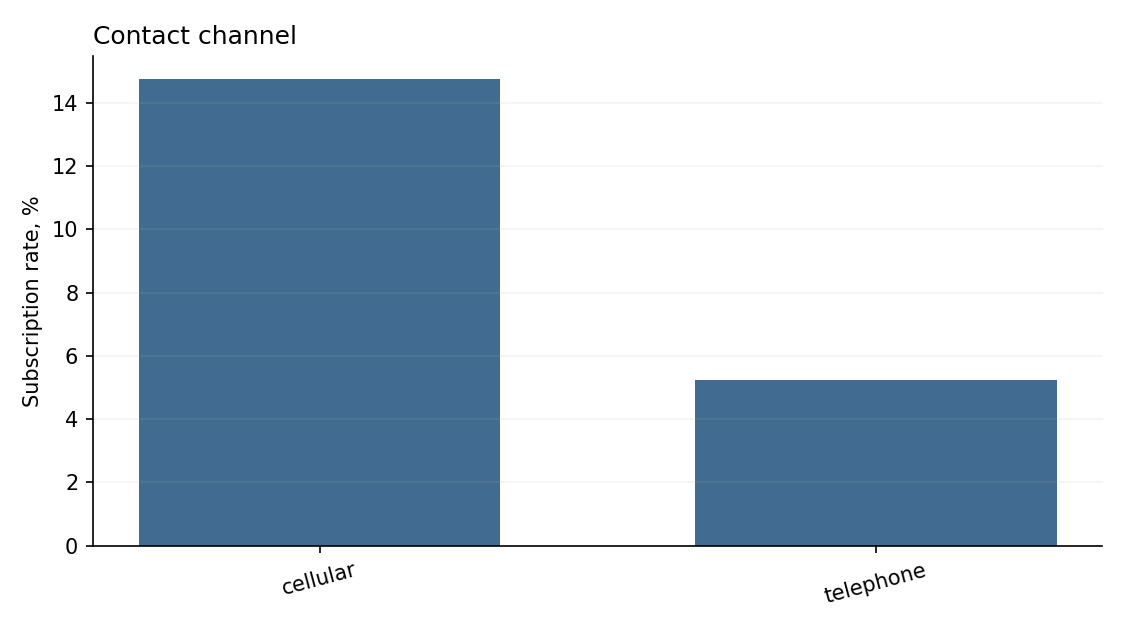

In [4]:
print(tables["02_contact"].to_string(index=False))
print()
print(tables["03_previous_outcome"].to_string(index=False))
display(Image(filename="reports/contact.png"))

Разница каналов большая, но это наблюдательные данные. Влияние канала нельзя отделить от состава клиентов и условий кампании. Прошлый успех выделяет сегмент с высокой долей оформлений, но он небольшой.

contact_band  observations  subscriptions  conversion_pct
           1         17642           2300           13.04
           2         10570           1211           11.46
           3          5341            574           10.75
         4-5          4250            369            8.68
          6+          3385            186            5.49


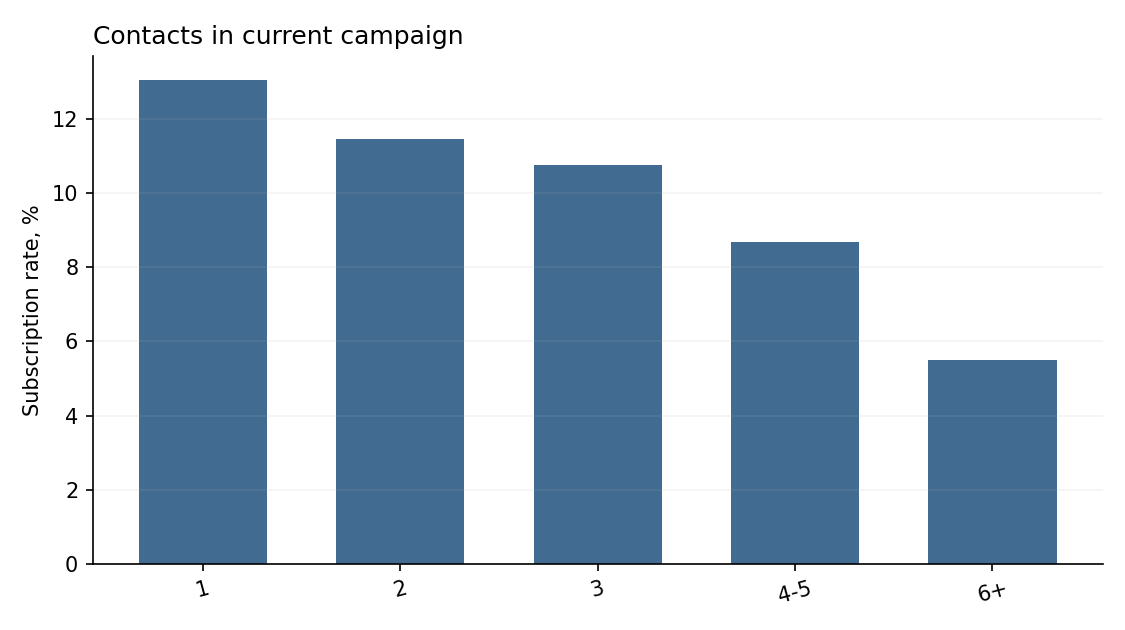

In [5]:
print(tables["04_contact_pressure"].to_string(index=False))
display(Image(filename="reports/pressure.png"))

При 6+ контактах конверсия 5,49% против 13,04% при одном. Возможна обратная причинность: больше попыток требуется для менее заинтересованных клиентов. Этот срез не доказывает вред дополнительных звонков.

In [6]:
print(tables["05_segments"].to_string(index=False))
connection.close()

          job  observations  subscriptions  conversion_pct  subscription_share_pct  conversion_rank
      student           875            275           31.43                    5.93                1
      retired          1720            434           25.23                    9.35                2
   unemployed          1014            144           14.20                    3.10                3
       admin.         10422           1352           12.97                   29.14                4
   management          2924            328           11.22                    7.07                5
      unknown           330             37           11.21                    0.80                6
   technician          6743            730           10.83                   15.73                7
self-employed          1421            149           10.49                    3.21                8
    housemaid          1060            106           10.00                    2.28                9


## Вывод

Высокая конверсия и большой вклад в общий результат — разные критерии. У студентов конверсия 31,43%, но у admin. больше оформлений в абсолютном выражении. Для следующей кампании можно проверить приоритизацию клиентов с успешным прошлым контактом и лимит повторных звонков.

Длительность разговора не используется для отбора до звонка. По месяцам без года нельзя делать вывод о сезонности. Денежных метрик и ROI в данных нет.